In [ ]:
# Create two regression models for each variable (Tmax and Tmin) that fits monthly value of gridded features to the variable

### FIX: Filter NAN for target variable when preparing df
# refer to B3_2

# WORKFLOW

# 1. Load dfs and format for fitting
# 2. Fit and tune RF + XGB regressor using Randomized Search CV
# 3. Implement a final model using final hyperparameters & rfecv (feature elimination)
# 4. Saved trained regressor model using joblib
# 5. Predict on test df and get accuracy metrics
# 6. Get permutation feature importance results 

In [ ]:
# Libraries
import os
import numpy as np  
import pandas as pd
import joblib
import json
import gc
import glob
import math
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold, KFold

# Path configuration
tmax_train_p = fr"..\Data_Temp\Processed\Monthly_downscaling\final_tmax_train_df.parquet"
tmax_test_p = fr"..\Data_Temp\Processed\Monthly_downscaling\final_tmax_test_df.parquet"

tmin_train_p = fr"..\Data_Temp\Processed\Monthly_downscaling\final_tmin_train_df.parquet"
tmin_test_p = fr"..\Data_Temp\Processed\Monthly_downscaling\final_tmin_test_df.parquet"

regressor_model_path = fr"..\Data_Temp\Processed\Monthly_downscaling\Saved_regressors"
rscv_results_path = fr"..\Data_Temp\Processed\Monthly_downscaling\RSCV_results"
validation_results_path = fr"..\Data_Temp\Processed\Monthly_downscaling\Validation_results"
hpt_results_path = fr"..\Data_Temp\Processed\Monthly_downscaling\HPT_results"

os.makedirs(regressor_model_path, exist_ok=True)
os.makedirs(rscv_results_path, exist_ok=True)
os.makedirs(validation_results_path, exist_ok=True)
os.makedirs(hpt_results_path, exist_ok=True)

# Configurations
random_state_num = 64
n_cores = 3
target_variable_tmax = 'IS_tmax_average'
target_variable_tmin = 'IS_tmin_average'
predictor_features_tmax = [
        'y', 'x',                                                                           # spatial coordinates
        'chirts_tmax_average', 'era5l_tmax_average', 'har_tmax_average',                    # tmax averages from all gridded products
        'chirts_tmax_max', 'chirts_tmax_min', 'chirts_tmax_std', 'chirts_dtr_std',          # seconday tmax variables from chirts
#        'ik_tmax_average',                                                                  # insitu kriged average 
        'gldas_air_temp', 'gldas_lwdown', 'gldas_specific_humidity',                        # gldas weather variables
        'gldas_surface_pressure', 'gldas_swdown',                   
        'evi_monthly_mean','evi_missing_fraction',                                          # monthly evi variables 
        'lst_d_monthly_mean', 'lst_d_missing_fraction', 'lst_n_monthly_mean',               # lst variables from modis 
        'lst_n_missing_fraction', 'lst_diff_monthly_mean', 'lst_diff_missing_fraction', 
        'elev_mean', 'elev_std', 'elev_max', 'elev_min', 'slope_mean', 'aspect_mean',       # elevation and fetch variables from dem
        'elev_smoothed', 'fetch_1000m_dist', 'fetch_1000m_dir',
        'fetch_500m_dist', 'fetch_500m_dir', 'local_relief', 
        'month_sin', 'month_cos']                                                            # cyclic encoded month variables

predictor_features_tmin = ['y', 'x', 
       'chirts_tmin_average', 'era5l_tmin_average', 'har_tmin_average', 
       'chirts_tmin_max', 'chirts_tmin_min','chirts_tmin_std', 'chirts_dtr_std', 
#       'ik_tmin_average',
       'gldas_air_temp', 'gldas_lwdown', 'gldas_specific_humidity',
       'gldas_surface_pressure', 'gldas_swdown', 
       'evi_monthly_mean', 'evi_missing_fraction', 
       'lst_d_monthly_mean', 'lst_d_missing_fraction', 'lst_n_monthly_mean', 
       'lst_n_missing_fraction', 'lst_diff_monthly_mean', 'lst_diff_missing_fraction', 
       'elev_mean', 'elev_std', 'elev_max', 'elev_min', 'slope_mean', 'aspect_mean',
       'elev_smoothed', 'fetch_1000m_dist', 'fetch_1000m_dir',
       'fetch_500m_dist', 'fetch_500m_dir', 'local_relief', 
       'month_sin', 'month_cos']

# Helpers

def get_param_grids():
    param_dist_rf = {
        'n_estimators':      [100, 500, 1000, 2000],
        'max_features':      ['sqrt', 'log2'],
        'max_depth':         [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf':  [1, 2, 4],
    }
    param_dist_xgb = {
        'n_estimators':     [500, 1000, 2000, 3000],
        'max_depth':        [3, 5, 7, 10],
        'learning_rate':    [0.01, 0.05, 0.1, 0.2],
        'subsample':        [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
        'gamma':            [0, 0.1, 0.5],
    }
    
    return param_dist_rf, param_dist_xgb

def compute_metrics(y_true, y_pred, label):
    """Compute RMSE, MAE, R² and print with label."""
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f"    [{label}]  RMSE={rmse:.4f}  MAE={mae:.4f}  R²={r2:.4f}  n={len(y_true)}")
    return {'rmse': round(rmse, 4), 'mae': round(mae, 4), 'r2': round(r2, 4),
            'n': len(y_true)}

In [ ]:
# 1. Load dfs and format for fitting

tmax_train_df = pd.read_parquet(tmax_train_p)
tmax_test_df = pd.read_parquet(tmax_test_p)
tmin_train_df = pd.read_parquet(tmin_train_p)
tmin_test_df = pd.read_parquet(tmin_test_p)

# Tmax train arrays
X_train_tmax = tmax_train_df[predictor_features_tmax].copy()
y_train_tmax = tmax_train_df[target_variable_tmax].copy()

# Tmax test arrays
X_test_tmax = tmax_test_df[predictor_features_tmax].copy()
y_test_tmax = tmax_test_df[target_variable_tmax].copy()

# Tmin train arrays
X_train_tmin = tmin_train_df[predictor_features_tmin].copy()
y_train_tmin = tmin_train_df[target_variable_tmin].copy()

# Tmax test arrays
X_test_tmin = tmin_test_df[predictor_features_tmin].copy()
y_test_tmin = tmin_test_df[target_variable_tmin].copy()

train_data = {
    'tmax': (X_train_tmax, y_train_tmax),
    'tmin': (X_train_tmin, y_train_tmin)
}

test_data = {
    'tmax': (X_test_tmax, y_test_tmax),
    'tmin': (X_test_tmin, y_test_tmin)
}

In [ ]:
# 2. Fit and tune RF + XGB regressor using Randomized Search CV

param_dist_rf, param_dist_xgb = get_param_grids()
hpt_results_df = pd.DataFrame()


for t_variable in ['tmax', 'tmin']:
    X_train, y_train = train_data[t_variable]
    X_test, y_test = test_data[t_variable]
    for model_type in ['rf', 'xgb']:
        # increase trees for -- tmax-xgb, tmin-xgb
        
        # Build base model pipeline
        if model_type == 'rf':
            base_model = Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('reg',     RandomForestRegressor(random_state=random_state_num, n_jobs=n_cores))
            ])
            param_dist = {f'reg__{k}': v for k, v in param_dist_rf.items()}
        else:
            base_model = Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('reg',     XGBRegressor(random_state=random_state_num, n_jobs=n_cores))
            ])
            param_dist = {f'reg__{k}': v for k, v in param_dist_xgb.items()}

        search_cv = RandomizedSearchCV(
            estimator=base_model,
            param_distributions=param_dist,
            n_iter=50,
            cv=5,
            verbose=1,
            random_state=random_state_num,
            n_jobs=n_cores,
            scoring='neg_root_mean_squared_error',
        )

        search_cv.fit(X_train, y_train)
        best_model = search_cv.best_estimator_
        
        rscv_results = pd.DataFrame(search_cv.cv_results_)
        rscv_results.to_csv(os.path.join(rscv_results_path, f"{t_variable}_{model_type}.csv"), index=False)

        best_params = search_cv.best_params_
        best_params_clean = {k.replace('reg__', ''): v for k, v in best_params.items()}

        test_metrics = compute_metrics(y_test, best_model.predict(X_test), f'Test Score: {t_variable} - {model_type}')

        
        summary_row = {
            't_variable': t_variable,
            'model_type': model_type,
            'test_rmse': test_metrics['rmse'],
            **best_params_clean
        }
        
        hpt_results_df = pd.concat([hpt_results_df, pd.DataFrame([summary_row])], ignore_index=True)

hpt_results_df.to_csv(os.path.join(hpt_results_path, "hpt_results.csv"), index=False)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
    [Test Score: tmax - rf]  RMSE=1.4945  MAE=1.1480  R²=0.9231  n=1322
Fitting 5 folds for each of 50 candidates, totalling 250 fits
    [Test Score: tmax - xgb]  RMSE=1.4893  MAE=1.1297  R²=0.9237  n=1322
Fitting 5 folds for each of 50 candidates, totalling 250 fits
    [Test Score: tmin - rf]  RMSE=1.9373  MAE=1.5185  R²=0.9043  n=1318
Fitting 5 folds for each of 50 candidates, totalling 250 fits
    [Test Score: tmin - xgb]  RMSE=1.9195  MAE=1.4739  R²=0.9060  n=1318


## Check point 1 ##
HPT set is saved above. Rerun from below.
Rerun the first two cells - imports and configurations + df to be fitted

In [ ]:
# %%
# 3. Implement a final model using final hyperparameters & rfecv (feature elimination)
# 4. Saved trained regressor model using joblib

hpt_results_df = pd.read_csv(fr"..\Data_Temp\Processed\Monthly_downscaling\HPT_results\hpt_results.csv")

def pick_model_parameters(t_var: str, hpt_df: pd.DataFrame):
    hpt_set = hpt_df[hpt_df['t_variable'] == t_var]
    
    rf_rmse = hpt_set[hpt_set['model_type'] == 'rf'].iloc[0]['test_rmse']
    xgb_rmse = hpt_set[hpt_set['model_type'] == 'xgb'].iloc[0]['test_rmse']
    
    if rf_rmse > xgb_rmse:
        select_model = 'xgb'
        select_param = hpt_set[hpt_set['model_type'] == 'xgb'].iloc[0][
            ['n_estimators', 'max_depth', 'subsample', 'learning_rate', 'gamma', 'colsample_bytree']
        ].to_dict()
    else:
        select_model = 'rf'
        select_param = hpt_set[hpt_set['model_type'] == 'rf'].iloc[0][
            ['n_estimators', 'min_samples_split', 'min_samples_leaf', 'max_features', 'max_depth']
        ].to_dict()
        
    return select_model, select_param

for t_var in ['tmax', 'tmin']:
    print(f"\nBuilding final model for {t_var}")
    model_type, parameter_set = pick_model_parameters(t_var, hpt_results_df)

    int_params = ['n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf']
    
    parameter_set = {
        key: (int(value) if key in int_params else value) 
        for key, value in parameter_set.items()
        if not (isinstance(value, float) and math.isnan(value))
    }
    
    X_train, y_train = train_data[t_var]
    feature_order = X_train.columns.tolist()

    if model_type == 'rf':
        model = RandomForestRegressor
    else: 
        model = XGBRegressor
    
    regressor = model(random_state=random_state_num, n_jobs=n_cores, **parameter_set)
    
    rfecv_regressor = RFECV(
        estimator=regressor, 
        step=2, 
        min_features_to_select=5,  
        cv=KFold(n_splits=5, shuffle=True, random_state=random_state_num),
        scoring='neg_mean_squared_error',
        n_jobs=n_cores
    )
    
    reg_selector = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('rfecv_reg', rfecv_regressor)
    ])
    
    reg_selector.fit(X_train, y_train)

    joblib.dump(reg_selector, os.path.join(regressor_model_path, f"{t_var}_{model_type}.pkl"))

    reg_support_mask = reg_selector.named_steps['rfecv_reg'].support_
    regressor_selected_features = [f for f, keep in zip(feature_order, reg_support_mask) if keep]
    print(f"  [Regressor] Optimal features selected: {len(regressor_selected_features)} / {X_train.shape[1]}")

    metadata = {
        'model_type': model_type,
        'input_features': feature_order,
        'selected_feature': regressor_selected_features
    }
    with open(os.path.join(regressor_model_path, f"{t_var}_{model_type}_feature_metadata.json"), 'w') as f:
        json.dump(metadata, f, indent=2)

    del (X_train, y_train, regressor, rfecv_regressor, reg_selector, reg_support_mask, regressor_selected_features, metadata)
    gc.collect()
    print(f"Final RFECV implemented model + Metadata saved for: {t_var}--{model_type}")


Building final model for tmax
  [Regressor] Optimal features selected: 28 / 36
Final RFECV implemented model + Metadata saved for: tmax--xgb

Building final model for tmin
  [Regressor] Optimal features selected: 26 / 36
Final RFECV implemented model + Metadata saved for: tmin--xgb


In [ ]:
# 5. Predict on test df and get accuracy metrics

for t_var in ['tmax', 'tmin']:

    X_test, y_test = test_data[t_var]

    model_file = glob.glob(os.path.join(regressor_model_path, f"{t_var}_*.pkl"))[0]
    model = joblib.load(model_file)
    metadata_file = glob.glob(os.path.join(regressor_model_path, f"{t_var}_*_feature_metadata.json"))[0]
    with open(metadata_file, 'r') as f:
        metadata = json.load(f)

    validation_results = compute_metrics(y_test, model.predict(X_test), f"{t_var}-{metadata['model_type']}")
    print(f"With features:{metadata['selected_feature']}")
    print("\n")

    [tmax-xgb]  RMSE=1.5093  MAE=1.1464  R²=0.9216  n=1322
With features:['y', 'x', 'chirts_tmax_average', 'era5l_tmax_average', 'har_tmax_average', 'chirts_tmax_max', 'chirts_tmax_min', 'gldas_air_temp', 'gldas_lwdown', 'gldas_specific_humidity', 'gldas_surface_pressure', 'gldas_swdown', 'lst_d_monthly_mean', 'lst_n_monthly_mean', 'elev_mean', 'elev_std', 'elev_max', 'elev_min', 'slope_mean', 'aspect_mean', 'elev_smoothed', 'fetch_1000m_dist', 'fetch_1000m_dir', 'fetch_500m_dist', 'fetch_500m_dir', 'local_relief', 'month_sin', 'month_cos']


    [tmin-xgb]  RMSE=1.9122  MAE=1.4753  R²=0.9067  n=1318
With features:['y', 'x', 'chirts_tmin_average', 'era5l_tmin_average', 'har_tmin_average', 'chirts_tmin_max', 'chirts_tmin_min', 'gldas_air_temp', 'gldas_lwdown', 'gldas_specific_humidity', 'gldas_surface_pressure', 'lst_d_monthly_mean', 'lst_n_monthly_mean', 'elev_mean', 'elev_std', 'elev_max', 'elev_min', 'slope_mean', 'aspect_mean', 'elev_smoothed', 'fetch_1000m_dist', 'fetch_500m_dist',

In [ ]:
# 6. Get permutation feature importance results

n_repeatsP = 10
max_samplesP = 50000
perm_jobsP = 1
r2_scorer = make_scorer(r2_score)

for t_var in ['tmax', 'tmin']:
    #load model & metadata
    X_test, y_test = test_data[t_var]

    model_file = glob.glob(os.path.join(regressor_model_path, f"{t_var}_*.pkl"))[0]
    model = joblib.load(model_file)
    metadata_file = glob.glob(os.path.join(regressor_model_path, f"{t_var}_*_feature_metadata.json"))[0]
    with open(metadata_file, 'r') as f:
        metadata = json.load(f)

    baseline_prediction = model.predict(X_test)
    baseline_score = r2_score(y_test, baseline_prediction)

    print("\nCalculating Individual Feature Importance")
    perm = permutation_importance(
        model, X_test, y_test,
        n_repeats=  n_repeatsP,
        random_state = random_state_num,
        n_jobs = perm_jobsP,
        scoring = r2_scorer
    )
    indiv_rows = []
    for i, feat in enumerate(X_test.columns):
        indiv_rows.append({
            'variable': t_var,
            'model': metadata['model_type'],
            'feature': feat,
            'importance_mean': round(perm.importances_mean[i], 6),
            'importance_std': round(perm.importances_std[i], 6)
        })
    individual_df = pd.DataFrame(indiv_rows).sort_values('importance_mean', ascending=False).reset_index(drop=True)
    individual_df['rank'] = individual_df['importance_mean'].rank(ascending=False, method='min').astype(int)
    individual_df.to_csv(os.path.join(validation_results_path, f"perm_imp_{t_var}_{metadata['model_type']}.csv"), index=False)


Calculating Individual Feature Importance

Calculating Individual Feature Importance


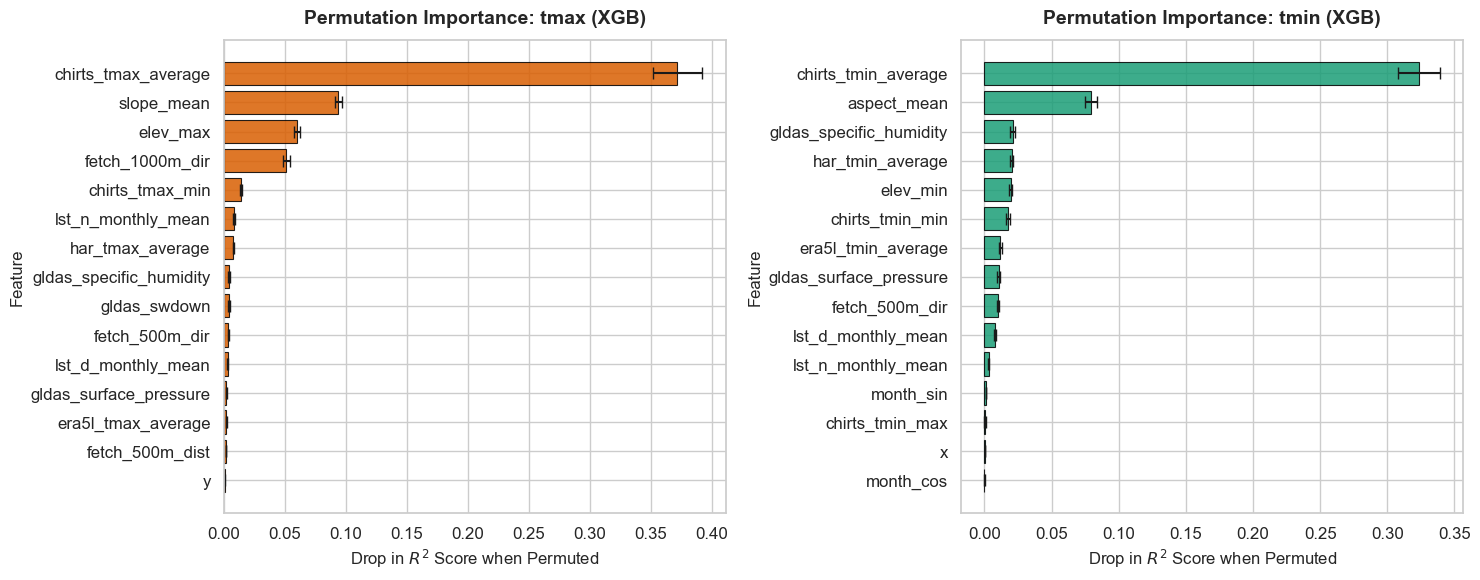

In [ ]:
# Display permutation feature importance results
# Set aesthetic style
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=False)

targets = ['tmax', 'tmin']
colors = ['#d95f02', '#1b9e77']  

for i, t_var in enumerate(targets):
    csv_file = glob.glob(os.path.join(validation_results_path, f"perm_imp_{t_var}_*.csv"))[0]
    df = pd.read_csv(csv_file)
    
    # Take top 10 most important features and sort for horizontal plot
    df_top = df.sort_values('importance_mean', ascending=True)
    
    # Plot horizontal bar chart with std dev error bars
    axes[i].barh(
        y=df_top['feature'], 
        width=df_top['importance_mean'], 
        xerr=df_top['importance_std'],
        color=colors[i],
        alpha=0.85,
        capsize=4,
        edgecolor='black',
        linewidth=0.8
    )
    
    # Titles and Labels
    model_name = df_top['model'].iloc[0].upper()
    axes[i].set_title(f"Permutation Importance: {t_var} ({model_name})", fontsize=14, fontweight='bold', pad=12)
    axes[i].set_xlabel("Drop in $R^2$ Score when Permuted", fontsize=12)
    axes[i].set_ylabel("Feature", fontsize=12)

plt.tight_layout()
plt.show()